# In-Class Assignment: Agent Based Modeling of Superbugs (part 2)
## With more code review!
# Day 09
# CMSE 202

<img src="https://raw.githubusercontent.com/s-macke/Abstruse-Goose-Archive/refs/heads/master/comics/you_down_wit_OPC-yeah_you_know_me.png" alt="Abstruse Goose webcomic riffing on using other people's code" width=600px>
<p style="text-align: right;">
    
Source: http://abstrusegoose.com/strips/you_down_wit_OPC-yeah_you_know_me.png ; thanks to Bruce Bolden</p>

<!--
<img src="http://abstrusegoose.com/strips/you_down_wit_OPC-yeah_you_know_me.png" width=600px>
<p style="text-align: right;">Amusing comic from: http://abstrusegoose.com/ </p>
-->

### <p style="text-align: right;"> &#9989; **Dhruti Bhat** </p>
#### <p style="text-align: right;"> &#9989; Ethan, Brook, Daniel</p>

## Learning Goals

By the end of this assignment you should be able to:
* Continue building (or complete) your agent-based "superbugs" model, then compare it against a provided solution
* Explore and use unfamiliar code with tools like `help()`, `dir()`, and `?`, and by reading the source
* Run the simulation as a numerical "experiment" and reason about its performance (what makes it slow)
* Formulate and test a scientific question using the model (e.g., the role of the mutation rate)

### How this connects to the course learning goals

Beyond today's specific goals above, this assignment builds toward these **course-level learning goals** (see the syllabus, or the Day 1 notebook, for the full CLG 1-7 list):

- **CLG 1 - Design and write programs to solve problems:** you'll build/complete your agent-based model and write the code to run simulations and experiments.
- **CLG 5 - Manipulate, analyze, and visualize datasets (and evaluate models):** you'll run the simulation, visualize its progress, and use it to answer a scientific question (e.g., how the mutation rate affects the outcome).
- **CLG 2 - Identify and use pre-existing tools and code:** you'll explore and use a provided solution (`superbugs.py`) with `help()`/`dir()`/`?` and by reading the source.
- **CLG 6 - Work in diverse groups:** you'll design, review code, and experiment together with your group.
- **CLG 4 - Use modern development methods:** you'll compare implementations and analyze the code's performance (finding what makes it slow).

## Agenda for today's class

- [Part 1: Pre-class assignment review and discussion](#pca-review)
- [Part 2: Revisiting your assignment from last class, building your Python class(es)](#revisit)
- [Part 3: Understanding someone else's code](#someone-else)
- [Part 4: Reviewing the provided code](#code-review)
- [Part 5: Running the simulation](#simulation)
- [Part 6: Testing Scientific Questions](#testing)

---
<a id="pca-review"></a>
## Part 1. Pre-class assignment review and discussion

Did anyone have any specific issues with the pre-class assignment?

Let's take a moment to highlight some key concepts. **Discuss with your group** the following prompts and write down a some brief notes from your discussion.

&#9989; **Question 1:** What did you see as some of the key differences, advantages, and disadvantages in the linear, functional, and object oriented programming approaches you reviewed in the pre-class assignment?

<font size=+3>&#9998;</font>I foudn linear to be the most inconveneitn for most situations becuase it's much longer and brute-forced than the others, and  not as organized. I think functional is better for when you want to work in parts becasue the code is borken down into seperate functions which makes it easier to modify and navigate. I liked the object oriented the most because not only is it organized but it is more detailed without being too much info all at once like linear. It seem sliek a good balance between the previous two programming types but also as usual has it's disadvantages

&#9989; **Question 2:** What is a Python "docstring", how it is used, and why is it useful?

<font size=+3>&#9998;</font> docstring is used to kind of break down what th ecode is saying into to descriptive steps. kind of like a long comment that describes the functions properties.

---
<a id="revisit"></a>
##  Part 2. Revisiting your assignment from last class, building your Python class(es)

Now that you've had a bit more time to think about object oriented programming and review some code that was written to build an agent-based model in an object oriented way, **you're going to spend the first 15 minutes of your group activity time picking up where you left off with your "superbugs" model.**

**&#9989; Do This:** Take this time to review the progress you made last class on initializing your petri dish. If you didn't finish it, try to finish it. If you finished it, review your code and think about ways you might be able to make it better. Reviewing your own code will sometimes feel like looking at someone else's code. You might find that your "present self" isn't a huge fan of how your "past self" did things (especially if your past self didn't leave you any comments!). **Do this as a group!**

Copy your code from last time into this notebook and try to get your petri dish code working or make improvements to a functioning version.

**If you already managed to get the basic petri dish initialization working, start building other methods that would be necessary to evolve the model**.

**If you do not get your own code working within the first 15 minutes, move on to part 3 and download a working version of the code.**

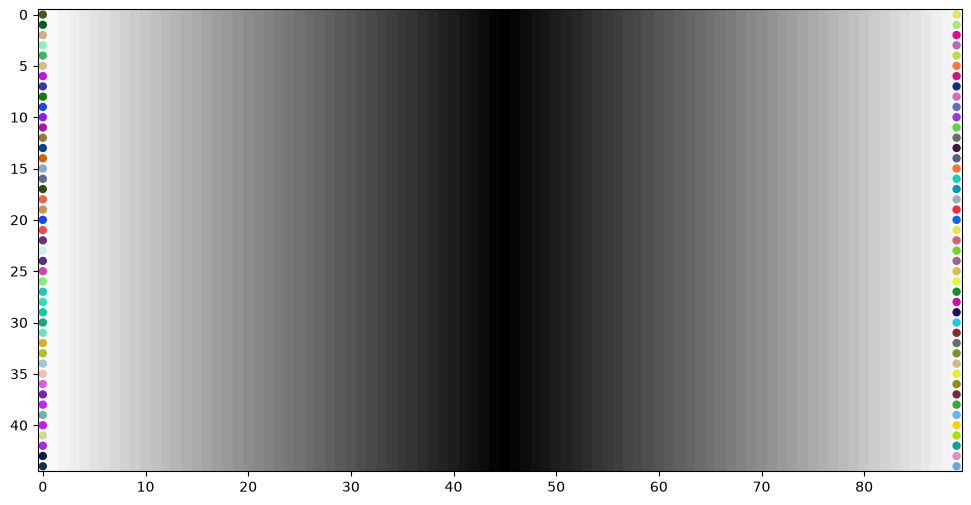

In [1]:
# CODE GOES HERE!
import numpy as np
import matplotlib.pyplot as plt
import random

#number of rows and columns to make a rectangle
n_rows = 45
n_cols = 90

#splits the graph in half to visualize the gradient
world = np.zeros((n_rows, n_cols, 3))
for col in range(n_cols):
    distance = abs(col-n_cols/2)/(n_cols/2)
    level = distance

    world[:, col, :] = [level, level, level]

#empty brackets for variables
bacteria_x=[]
bacteria_y=[]
bacteria_colors=[]

#assigns random colors for each of the bacterium  on both the left and right side
for row in range(n_rows):
    bacteria_x.append(0)
    bacteria_y.append(row)
    bacteria_colors.append(np.random.rand(3))

    bacteria_x.append(n_cols-1)
    bacteria_y.append(row)
    bacteria_colors.append(np.random.rand(3))
    
plt.figure(figsize=(12,6))
plt.imshow(world)

plt.scatter(bacteria_x, bacteria_y, c=bacteria_colors, s=25)

plt.show()

## &#128721; STOP

Check-in with the rest of the group and with the instructor

----
<a id="someone-else"></a>
## Part 3. Understanding someone else's code

In the pre-class assignment, you spent some time doing a code review of multiple solutions to the same problem. In addition to simply reading unfamiliar code to make sense of it, when we use a new bit of code, if it's reasonably well written there are ways to explore how it works from inside our Jupyter notebooks or within an IPython prompt as well.

Thus far you've spent a bit of time trying to write your own solution to the superbug problem in an effort to recreate the anti-bacterial resistance experiment. Maybe you got everything working the way you wanted, or perhaps you've still ironing out a few bugs. **Now we're going to switch gears a bit and look at one possible complete solution to the problem**.

**&#9989; Do This:** To start, you're going to import a script that contains this solution. First, you need to download the script, `superbugs.py`, which you can get here:

`https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/main/code_samples/superbugs.py`

**Run the following cell to import the script once you download it.**

In [2]:
!curl -O https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/main/code_samples/superbugs.py

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  9440  100  9440    0     0  75336      0 --:--:-- --:--:-- --:--:-- 75520


In [3]:
import superbugs

&#9989; **Do This:** Now, explore the above software, but **don't just look at the code right now**. Use standard exploration commands (e.g. use `help()`, `dir()`, `type`, or `?`) in your notebook to see if you can figure out what "`superbugs`" does/can do.

In [4]:
# put your exploration code here.
help(superbugs)

Help on module superbugs:

NAME
    superbugs - superbugs.py

DESCRIPTION
    Contains class definitions for modeling the evolution of bacteria in the
    presence of antibiotics.

CLASSES
    builtins.object
        Bug
        PetriDish

    class Bug(builtins.object)
     |  Bug(c=0, r=0, mutation_rate=0.2, active=True)
     |
     |  Bug class.
     |
     |  Each bug has 3 genes in the range [0, 1) and a location (c, r) in
     |  a two dimensional grid.
     |
     |  Attributes:
     |      genes [type: numpy array]
     |          List of three numbers in the range [0, 1) generated uniformly
     |          at random.
     |
     |      loc [type: tuple]
     |          Ordered pair of coordinates specifying the bug's location.
     |
     |      active [type: bool]
     |          True if the bug is alive (capable to reproduce), False if it is dead.
     |
     |      mutation_rate [type: float]
     |          The mutation rate for the bacterium
     |
     |  Methods:
     |

&#9989; **Do This:** Using the superbugs code, initialize the experiment and display the first time step of the board (t=0). Then, try to take a timestep and visualize the result. Again, **see if you can do this _without_ looking at the source code**.

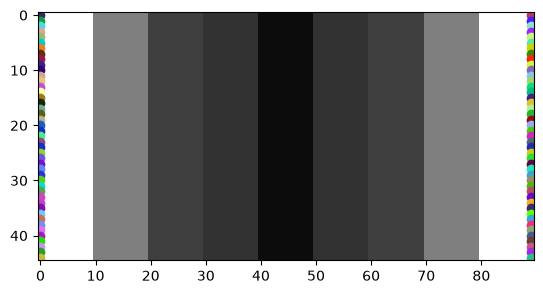

In [5]:
# put your initialization and visualization code here
petri_dish = superbugs.PetriDish()
petri_dish.draw()
plt.show()

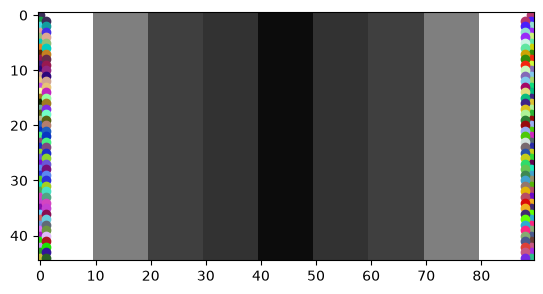

In [6]:
# put your code for taking a step and visualizing the code here
petri_dish.timestep()
petri_dish.draw()
plt.show()

---
<a id="code-review"></a>
## Part 4. Reviewing the provided code

OK, now that you've managed to learn a bit about the the code to the point where you can initialize the simulation, you're going to take a look at the code and see how it compares to what you came up with.

&#9989; **Do This:** Open `superbugs.py` in a text editor and review the code. How does it work, what classes are available? What are their associated methods and attributes? **Compare and constrast the code with the code that you wrote** (even if you didn't get all bits of your code working). **What parts are similar? What parts are different? What advantages/disadvantages do you see in your approach and this approach?** Discuss this with your group and write down some notes from your discussion.

**If there are parts of the code that you don't understand, talk with your group or ask an instructor for help!**

<font size=+3>&#9998;</font> the code seems like it follows object oriented programming because it really emohasizes the different classes and objects used and methods within. for example, the classes avaible are bug and petridish, and they each have well organized and detailed methods and attributes. I the biggest differnece is tha ti followed a mroe funcitonal programming aproach rather thann object oriented. I think that made my code harder to interpret because it wasnt explained specifically waht each row is doing and that confused me when i revisted it for the first time agiaan today.  I think the only advantage of my code is that it's more compact and quick to skim over but it doesnt detail the code. I like that the source code uses only 2 classes but gives them extensive detail so it was veyr easy to understand

## &#128721; STOP

Check-in with the rest of the group and with the instructor.

----
<a id="simulation"></a>
## Part 5. Running the Simulation

Now that you understand a bit about how the code works, you're going to try to run a full simulation for a set number of timesteps.

&#9989; **Do This:** Using the petri_dish variable you initialized previously, write an loop that runs the ```timestep``` function followed by the ```draw``` function 10 times.  Make sure to animate the figure (you might need to dig up a previous example to get the animation working).

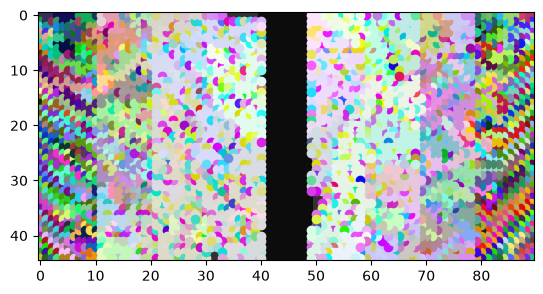

10.57526445388794


In [8]:
# Put your code here
import time

#start = time.time()
#for i in range(10):
#    petri_dish.timestep()
#    petri_dish.draw()
#    plt.pause(0.1)
#end = time.time()
#print(end - start)
#24.11945080757141

start = time.time()
for i in range(100):
    petri_dish.timestep()

petri_dish.draw()
plt.show()
end = time.time()
print(end - start)
#10.57526445388794

&#9989; **Do This:** You might have noticed that the simulation gets slower as it runs.  **Comment out the plotting and animation code and rerun the simulation with 100 iterations.** Only draw the simulation once it is complete.

&#9989; **Question 3**: Do you notice a change in the simulation run time when you comment out the plotting and animation code? How can you tell?

<font size=+3>&#9998;</font> yes it took a lot longer to run and load the graph

&#9989; **Do This**: Now consider an optimized version of the Superbugs code. Download the code from the url below. And then attempt to run a new simulation with 100 generations while animating it each generation, similar to the beginning of part 5. 

`https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/main/code_samples/superbugsOpt.py`

In [14]:
!curl -O https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/main/code_samples/superbugsOpt.py

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  9884  100  9884    0     0   276k      0 --:--:-- --:--:-- --:--:--  283k


&#9989; **Question 4**: How much faster did the code run compared to the original animated version? Looking at the new code, why do you think it ran faster?

<font size=+3>&#9998;</font> It ran slightly faster than before and i think its because it doesnt have to create a bunch of different graphs and does it all in one

&#9989; **Question 5**: What if you wanted to know exactly how long it took to run the simulation? You might have used the `time` module in your animation code or in previous code you've worked with, but we can also use it to time how long certain pieces of code take to run. We can record an initial time with something like:

`start = time.time()`

And then record the time the code finishes with:

`end = time.time()`

Try adding this to your code above to time exactly how long the simulation took in each scenario. Add a line to **print the difference between end and start time to get the total runtime (in seconds)**. Try comparing the total run times between the first version, the version without the animation, and the optimized version.

**What is the difference in the timing between the versions explored?**

<font size=+3>&#9998;</font> the difference is approx. 14 seconds

&#9989; **Question 6**: What if you wanted to know how long each step of the simulation took (i.e. each iteration of the loop)? How would you track this information in your code? **If you have time at the end of class, come back to this and try implementing some code that tracks the time that each step took and prints or visualizes the results.**

<font size=+3>&#9998;</font> Do This - Erase the contents of this cell and replace it with your answer to the above question!  (double-click on this text to edit this cell, and hit shift+enter to save the text)

---
<a id="testing"></a>
## Part 6. Testing Scientific Questions

For the remainder of the class, we are going to use this code to ask some scientific questions.

&#9989; **Do This:** Discuss as a group/class the types of scientific question can you could ask (and potentially answer) using this type of simulation.

<font size=+3>&#9998;</font> how does the mutation rate affects the survival of the bugs? how does the antibiotic strength affects the number of surviving bugs? how quickly do the bugs spread across the petri dish?


&#9989; **Question 7:** Given the above questions, what types of measurements or modifications might we need to add to the superbug code?

<font size=+3>&#9998;</font> we would need to change the mutation rate and measure the number of bugs that have survived after a certain timestep. the simulation could e run several times with different mutation rates to compare results.

&#9989; **Do This:** Do this, modify or use the simulation in some way that allows you to test a scientific question of the simulation.

In [10]:
# put your scientific experiment code here.
mutation_rates = [0.0, 0.1, 0.2, 0.3, 0.5]
survivors = []

for rate in mutation_rates:
    petri_dish = superbugs.PetriDish(bug_mutation_rate=rate)
    
    for i in range(20):
        petri_dish.timestep()
    
    alive = sum(bug.active for bug in petri_dish.buglist)
    survivors.append(alive)

print(survivors)

[160, 165, 84, 82, 35]


&#9989; **Question 8**: What scientific question does your new usage or modification demonstrate and what can you conclude from the simulation?

<font size=+3>&#9998;</font> The question was how the mutation rate affects the survival of bacteria and the simulation showed that changing the mutation rate changes the number of surviving bugs after 20 timesteps. In the simulation the mutation rate of 0.1 resulted in the most surviving bugs, while the highest mutation rate tested resulted in fewer survivors. This shows that the mutation rate can affect how well the bacteria survive in the presence of antibiotics.

### Visualizing the progress of the superbugs

If we wanted to use this simulation to answer one of your scientific questions, we might want to visualize the progress of the superbugs as a function of time as they march across the petri dish.

&#9989; **Do This:** Write some code to show, in one graph, the progress of the simulation.  For example: you could plot the number of iterations on the x axis and the progress the bugs have made toward the center of the simulation on the y axis.

-----
### Congratulations, we're done!

Now, you just need to submit this assignment by uploading it to the course <a href="https://d2l.msu.edu/">Desire2Learn</a> web page for today's submission folder (Don't forget to add your names in the first cell).

&#169; Copyright 2026, Department of Computational Mathematics, Science and Engineering at Michigan State University